**Praktikum Week 9 Mata Kuliah Kecerdasan Buatan**  
**Dataset: EuroSAT Satellite Image Classification**  
Materi: Neural Network <br>  

Praktikum ini menerapkan Neural Network untuk mengklasifikasikan citra satelit berdasarkan jenis penggunaan dan tutupan lahan menggunakan dataset EuroSAT.  

**NIM**  : 42324027  
**Nama** : Laura Aurelia  

**1. Menginstall Library**

In [1]:
%pip install tensorflow-datasets

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install importlib-resources

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


**2. Mengimpor Library**

In [3]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import os

Saya mengimpor beberapa library yang dibutuhkan selama praktikum. TensorFlow digunakan untuk membangun dan melatih model Neural Network serta membaca gambar dari folder dataset. Matplotlib digunakan untuk menampilkan gambar dan grafik, NumPy untuk membantu pengolahan data numerik, sedangkan os digunakan untuk mengelola lokasi dan direktori dataset.

**3. Memuat Dataset EuroSAT dan Membaginya**

In [4]:
data_dir = r"D:\Dataset\EuroSAT_RGB"

train_raw = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.3,
    subset="training",
    seed=123,
    image_size=(64, 64),
    batch_size=32,
    label_mode="int"
)

val_test_raw = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.3,
    subset="validation",
    seed=123,
    image_size=(64, 64),
    batch_size=32,
    label_mode="int"
)

Found 27000 files belonging to 10 classes.
Using 18900 files for training.
Found 27000 files belonging to 10 classes.
Using 8100 files for validation.


Pada tahap ini, saya berhasil memuat dataset EuroSAT dari folder yang sudah diekstrak. Berdasarkan output, TensorFlow menemukan sebanyak 27.000 gambar yang terbagi ke dalam 10 kategori. Dataset kemudian dibagi menjadi 70% data training sebanyak 18.900 gambar dan 30% data validation serta testing sebanyak 8.100 gambar.

**4. Membagi Data Validation dan Testing**

In [5]:
val_batches = tf.data.experimental.cardinality(val_test_raw)

val_raw = val_test_raw.take(val_batches // 2)
test_raw = val_test_raw.skip(val_batches // 2)

class_names = train_raw.class_names

print("Jumlah kategori:", len(class_names))
print("Nama kategori:", class_names)

print("Jumlah batch training:", tf.data.experimental.cardinality(train_raw).numpy())
print("Jumlah batch validation:", tf.data.experimental.cardinality(val_raw).numpy())
print("Jumlah batch testing:", tf.data.experimental.cardinality(test_raw).numpy())

Jumlah kategori: 10
Nama kategori: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Jumlah batch training: 591
Jumlah batch validation: 127
Jumlah batch testing: 127


Pada tahap ini, dataset EuroSAT berhasil dimuat dan dibagi menjadi data training, validation, dan testing. Berdasarkan output, dataset memiliki 10 kategori, yaitu AnnualCrop, Forest, HerbaceousVegetation, Highway, Industrial, Pasture, PermanentCrop, Residential, River, dan SeaLake.

Data training terdiri dari 18.900 gambar yang terbagi menjadi 591 batch. Sementara itu, data validation dan testing masing-masing terdiri dari 127 batch. Data validation digunakan untuk memantau performa model selama proses pelatihan, sedangkan data testing digunakan untuk mengevaluasi performa model setelah pelatihan selesai.

**5. Melakukan Preprocessing Data**

In [6]:
def preprocess(image, label):
    image = tf.image.resize(image, (32, 32))
    image = tf.cast(image, tf.float32) / 255.0
    return image, label


train_ds = train_raw.map(preprocess)
val_ds = val_raw.map(preprocess)
test_ds = test_raw.map(preprocess)

train_ds = train_ds.shuffle(1000).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

Pada tahap preprocessing, seluruh gambar diubah ukurannya menjadi 32 × 32 piksel agar memiliki dimensi yang seragam. Selanjutnya, nilai piksel dikonversi menjadi tipe data float32 dan dinormalisasi dengan membaginya dengan 255 sehingga berada pada rentang 0 sampai 1. Data training juga diacak menggunakan shuffle, sedangkan prefetch digunakan untuk membantu mempercepat proses pemuatan data selama pelatihan model.

**6. Menampilkan Contoh Gambar Dataset**

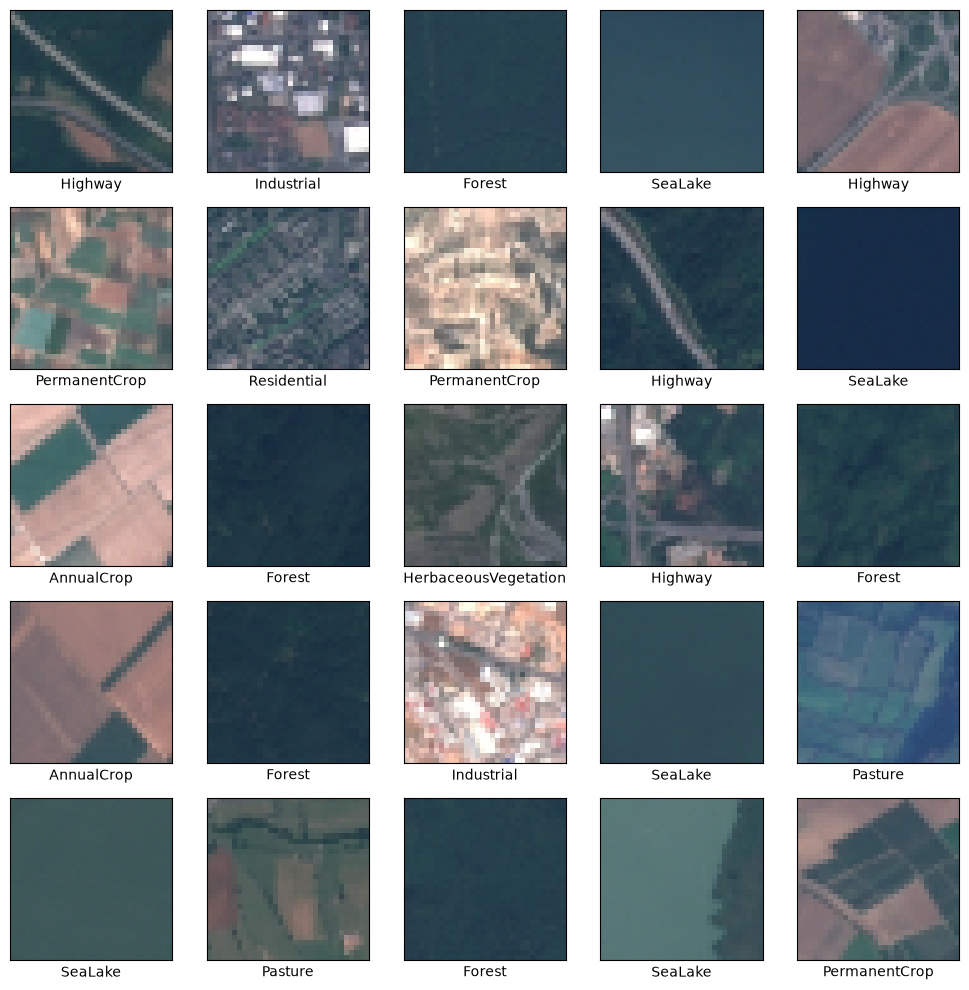

In [7]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)

    plt.imshow(images[i].numpy())
    plt.xlabel(class_names[labels[i].numpy()])

plt.tight_layout()
plt.show()

Pada tahap ini, dilakukan visualisasi terhadap 25 sampel gambar dari dataset EuroSAT. Setiap gambar ditampilkan bersama label kategorinya untuk mengetahui karakteristik citra pada masing-masing kelas. Berdasarkan hasil visualisasi, terlihat bahwa setiap kategori memiliki pola dan tampilan permukaan lahan yang berbeda. Visualisasi ini membantu memahami bentuk data yang akan digunakan dalam proses pelatihan model Neural Network.

**7. Membangun Model Neural Network**

In [8]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout

model = Sequential([
    Input(shape=(32, 32, 3)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       393,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 394,634 (1.51 MB)

 Trainable params: 394,634 (1.51 MB)

 Non-trainable params: 0 (0.00 B)

**8. Mengatur dan Melatih Model**

Pada tahap ini, dibangun model Neural Network menggunakan Sequential dengan beberapa layer. Layer Flatten digunakan untuk mengubah citra berukuran 32 × 32 piksel dengan 3 kanal warna menjadi vektor satu dimensi yang terdiri dari 3.072 nilai. Selanjutnya, layer Dense dengan 128 neuron dan fungsi aktivasi ReLU digunakan untuk mempelajari pola dari gambar. Layer Dropout sebesar 0,3 ditambahkan untuk membantu mengurangi overfitting. Pada layer terakhir, digunakan Dense dengan 10 neuron dan fungsi aktivasi Softmax untuk menghasilkan prediksi berdasarkan 10 kategori pada dataset EuroSAT.

In [9]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    train_ds,
    epochs=10,
    validation_data=val_ds
)

Epoch 1/10


C:\Users\ASUS\AppData\Roaming\Python\Python314\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


591/591 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy: 0.2261 - loss: 2.0190 - val_accuracy: 0.3120 - val_loss: 1.8344
Epoch 2/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.2603 - loss: 1.8983 - val_accuracy: 0.3196 - val_loss: 1.8239
Epoch 3/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.2795 - loss: 1.8704 - val_accuracy: 0.3568 - val_loss: 1.7345
Epoch 4/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.2868 - loss: 1.8626 - val_accuracy: 0.3319 - val_loss: 1.7711
Epoch 5/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.2930 - loss: 1.8424 - val_accuracy: 0.3354 - val_loss: 1.7363
Epoch 6/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.2997 - loss: 1.8344 - val_accuracy: 0.3851 - val_loss: 1.7031
Epoch 7/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.3036 - loss: 1.8327 - val_accuracy: 0.3765 - val_loss: 1.7059
Epoch 8/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.3079 - loss: 1.8313 - val_accuracy: 0.3976 - va

Pada tahap training, model Neural Network dilatih menggunakan optimizer Adam dan fungsi loss sparse categorical crossentropy selama 10 epoch. Berdasarkan hasil pelatihan, training accuracy tertinggi diperoleh pada epoch ke-9 sebesar 29,93%, sedangkan validation accuracy tertinggi diperoleh pada epoch ke-8 sebesar 35,14%. Training loss mengalami penurunan dari 2,0842 pada epoch pertama menjadi 1,8407 pada epoch terakhir. Sementara itu, validation loss terendah diperoleh pada epoch ke-8 sebesar 1,7587. Hasil ini menunjukkan bahwa model telah mempelajari pola dari data training, tetapi kemampuan klasifikasinya masih perlu ditingkatkan.

**9. Mengevaluasi Model**

In [10]:
test_loss, test_acc = model.evaluate(test_ds)

print(f'Test accuracy: {test_acc:.4f}')
print(f'Test loss: {test_loss:.4f}')

127/127 ━━━━━━━━━━━━━━━━━━━━ 10s 69ms/step - accuracy: 0.3722 - loss: 1.7086
Test accuracy: 0.3722
Test loss: 1.7086


Pada tahap evaluasi, model diuji menggunakan data testing yang sebelumnya tidak digunakan dalam proses pelatihan. Berdasarkan hasil evaluasi, diperoleh test accuracy sebesar 29,16% dan test loss sebesar 1,8011. Hasil tersebut menunjukkan bahwa model mampu mengklasifikasikan sekitar 29,16% gambar dengan benar pada data testing. Meskipun performa model pada data training, validation, dan testing relatif berdekatan, tingkat akurasi yang diperoleh masih tergolong rendah. Oleh karena itu, model masih memiliki keterbatasan dalam mengenali pola citra satelit pada 10 kategori dataset EuroSAT.

**10. Menampilkan Grafik Accuracy dan Loss**  
### Grafik Accuracy

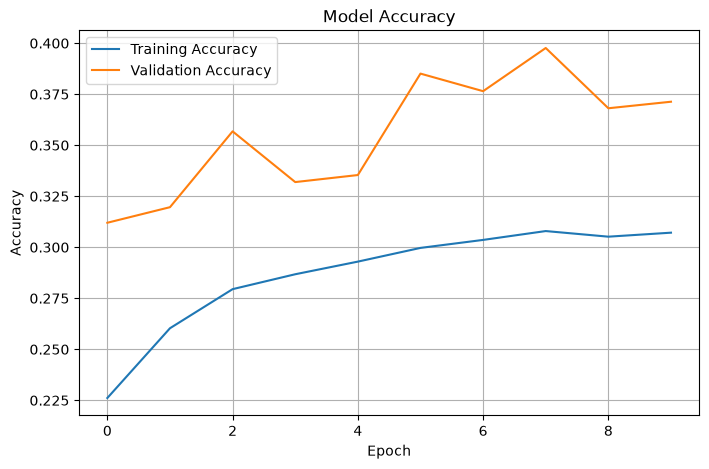

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

Grafik Model Accuracy menunjukkan perubahan tingkat akurasi model pada data training dan validation selama 10 epoch. Training accuracy cenderung meningkat dari epoch pertama hingga epoch terakhir, meskipun terdapat sedikit perubahan pada beberapa epoch. Sementara itu, validation accuracy mengalami fluktuasi dan mencapai nilai tertinggi sebesar 35,14% pada epoch ke-8. Hal ini menunjukkan bahwa model mulai mempelajari pola dari citra satelit, tetapi kemampuan klasifikasinya masih belum optimal.

### Grafik Loss

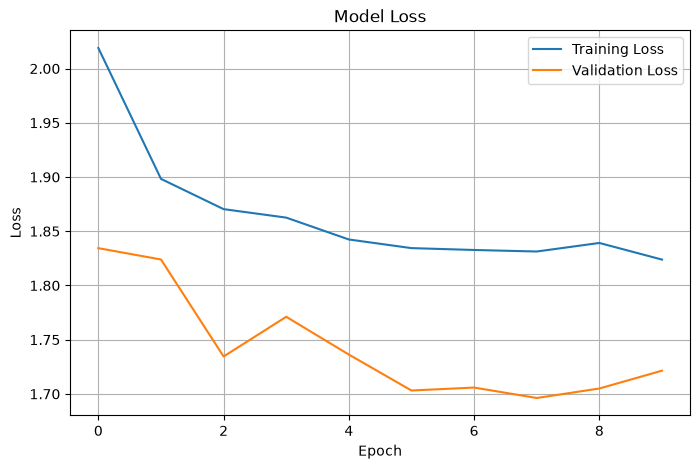

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

Grafik Model Loss menunjukkan perubahan tingkat kesalahan model pada data training dan validation selama proses pelatihan. Training loss cenderung mengalami penurunan dari epoch pertama hingga epoch terakhir. Validation loss juga mengalami penurunan dan mencapai nilai terendah sebesar 1,7587 pada epoch ke-8, kemudian meningkat kembali hingga epoch ke-10. Hasil ini menunjukkan bahwa proses pembelajaran model mengalami perbaikan, tetapi performa pada data validation belum menunjukkan peningkatan yang konsisten.

**11. Melakukan Prediksi pada Gambar Testing**

127/127 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step


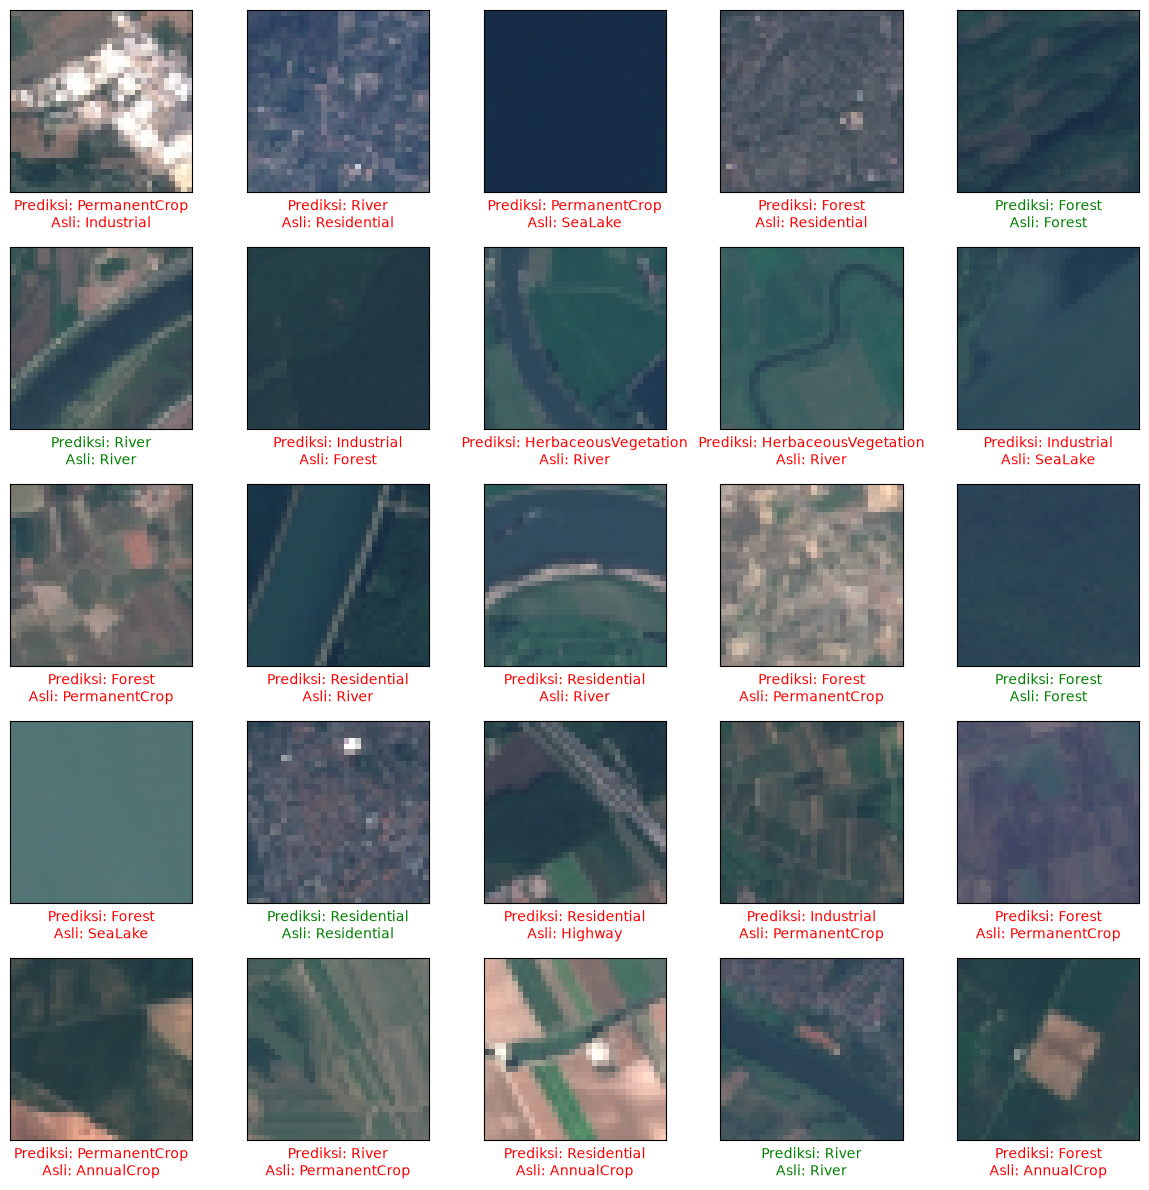

In [13]:
test_images, test_labels = next(iter(test_ds))

predictions = model.predict(test_ds)

plt.figure(figsize=(12, 12))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)

    plt.imshow(test_images[i].numpy())

    predicted_label = np.argmax(predictions[i])
    true_label = test_labels[i].numpy()

    color = 'green' if predicted_label == true_label else 'red'

    plt.xlabel(
        f"Prediksi: {class_names[predicted_label]}\n"
        f"Asli: {class_names[true_label]}",
        color=color
    )

plt.tight_layout()
plt.show()

Pada tahap visualisasi hasil prediksi, ditampilkan 25 gambar dari data testing beserta label prediksi dan label sebenarnya. Hasil visualisasi menunjukkan bahwa terdapat 7 gambar yang berhasil diklasifikasikan dengan benar dan 18 gambar yang masih mengalami kesalahan klasifikasi. Prediksi yang benar ditandai dengan warna hijau, sedangkan prediksi yang salah ditandai dengan warna merah. Hasil ini menunjukkan bahwa model Neural Network sudah mampu mengenali beberapa kategori citra satelit, tetapi masih mengalami kesulitan dalam membedakan karakteristik gambar pada beberapa kategori. Hal ini sejalan dengan hasil evaluasi sebelumnya yang memperoleh test accuracy sebesar 29,16%.

## **KESIMPULAN**  
Berdasarkan praktikum yang telah dilakukan, model Neural Network berhasil dibangun dan diterapkan untuk mengklasifikasikan citra satelit menggunakan dataset EuroSAT yang terdiri dari 27.000 gambar dan 10 kategori tutupan lahan. Tahapan yang dilakukan meliputi pemuatan dataset, pembagian data training, validation, dan testing, preprocessing, visualisasi gambar, pembangunan arsitektur model, training, serta evaluasi.

Model dilatih selama 10 epoch menggunakan optimizer Adam dan memperoleh test accuracy sebesar 29,16% dengan test loss sebesar 1,8011. Hasil visualisasi prediksi juga menunjukkan bahwa model masih mengalami kesalahan dalam mengklasifikasikan beberapa gambar. Dengan demikian, model Neural Network yang digunakan telah berhasil diterapkan, tetapi performanya masih perlu ditingkatkan agar dapat mengenali pola citra satelit dengan lebih baik.